# Robust drift estimation with a one-use-per-scene *matching bootstrap*

**A synthetic-data demonstration.**

The current all-patches drift pipeline (1) finds matched scene pairs per patch, (2)
median-collapses each acquisition pair across its spatial-replicate patches, then
(3) fits a Theil–Sen slope of $\Delta R$ vs $\Delta t$ over *all* the collapsed pairs.
That fit treats every pair as an independent, equally-reliable sample. It isn't, and
this notebook shows why and prescribes a fix.

Two defects, one root cause — **the pairs are a graph on a much smaller set of scenes**:

1. **Over-representation / leverage (graph structure).** A scene's number of matched
   pairs is its *degree* in the sun-angle-matching graph. Fitting all $O(\text{scenes}^2)$
   pairs claims far more independent information than the $\sim O(\text{scenes})$ we
   actually have, and a single biased scene contaminates *every* pair it touches — a
   correlated error Theil–Sen's per-*pair* robustness does not defend against.
2. **Hidden surface heterogeneity.** The median-collapse treats spatial-replicate
   patches as interchangeable replicates of one measurement and throws away the
   between-patch spread — but different patches are different ground with different
   BRDF and stability. That discarded spread is real uncertainty.

**The fix demonstrated here:** repeatedly draw a *matching* on the scene graph (each
scene used at most once → pairs are genuinely independent, every scene's leverage
capped at one pair), draw one patch's $\Delta R$ per pair (so surface heterogeneity
flows into the answer instead of being medianed away), fit a slope, and repeat. The
spread of slopes is an honest, bootstrap-style confidence interval — the same
philosophy already used in the BRDF step.

We build synthetic data with a **known** drift $\gamma_\text{true}$ so we can check
which estimator actually recovers the truth.

## 1. Setup and ground-truth parameters

We simulate one PICS: `N_SCENES` acquisitions over `YEARS`, each with a seasonal solar
zenith angle (SZA); `N_PATCHES` spatial-replicate patches inside the PICS; a **true**
sensor drift `GAMMA_TRUE` (%/yr) that is spatially uniform (it is a sensor property);
per-patch drift deviations `SIGMA_SURF` that encode surface heterogeneity (defect 2);
and a single over-represented scene carrying a `BIAS_PCT` bias (defect 1).

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.stats import theilslopes

rng = np.random.default_rng(42)

# ---- ground-truth simulation parameters ----
N_SCENES   = 60      # EMIT acquisitions across the record
N_PATCHES  = 12      # spatial-replicate patches inside the PICS
YEARS      = 4.0     # length of record (years)
GAMMA_TRUE = -2.0    # TRUE sensor drift, %/yr  <-- what every estimator should recover
SIGMA_SURF = 0.6     # per-patch drift heterogeneity, %/yr  (defect 2)
NOISE_PCT  = 0.4     # per-(scene,patch) measurement noise, % reflectance
BIAS_PCT   = 5.0     # bias injected into ONE over-represented scene (defect 1)

SZA_TOL     = 2.0    # deg; matched-pair sun-angle tolerance (mirrors run_config sza_tol)
MIN_DT_DAYS = 150    # require real temporal separation so a pair carries drift leverage

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.grid']  = True
plt.rcParams['grid.alpha'] = 0.3

## 2. Scenes: time and solar geometry

Each scene is one acquisition with a time `t_yr` and a mean in-patch `SZA`. The SZA
follows a strong **seasonal cycle**, so a scene matches (same sun angle) mostly scenes
from the *same season in other years*. This is exactly how real PICS matched pairs form
and it gives the graph its structure.

In [2]:
t = np.sort(rng.uniform(0, YEARS, N_SCENES))                 # acquisition times (yr)
SZA = 30 + 15*np.cos(2*np.pi*(t - 0.05)) + rng.normal(0, 0.4, N_SCENES)

scenes = pd.DataFrame({'scene': np.arange(N_SCENES), 't_yr': t, 'SZA': SZA})
scenes.head()

,scene,t_yr,SZA
0,0,0.029449,44.528791
1,1,0.175215,40.979571
2,2,0.255269,33.487365
3,3,0.376709,22.913037
4,4,0.458120,17.495989


## 3. The matched-pair graph

Two scenes form an **edge** (an admissible matched pair) when their SZA agree within
`SZA_TOL` **and** they are separated by at least `MIN_DT_DAYS`. Nodes = scenes; the graph
degree of a scene is how many pairs it belongs to — the seed of the over-representation
problem.

In [3]:
edges = []                                     # (i, j) admissible pairs, i < j
for i in range(N_SCENES):
    for j in range(i+1, N_SCENES):
        if abs(SZA[i]-SZA[j]) <= SZA_TOL and (t[j]-t[i])*365.0 >= MIN_DT_DAYS:
            edges.append((i, j))
edges = np.array(edges)
deg = np.bincount(edges.ravel(), minlength=N_SCENES)     # degree per scene

print(f"{len(edges)} admissible matched pairs among {N_SCENES} scenes")
print(f"scene degree -> min {deg.min()}, median {int(np.median(deg))}, max {deg.max()}")

153 admissible matched pairs among 60 scenes
scene degree -> min 1, median 6, max 11


## 4. Patches, coverage, and reflectance

Each patch has a static brightness `b_p` and a small **per-patch drift deviation**
`delta_p` (surface heterogeneity — different ground drifts slightly differently in
apparent terms). Each scene covers a random subset of patches (a granule footprint).

We then plant the bias in the **most-connected scene** — the single most damaging place
to hide it — and also give that scene full spatial coverage, so it is over-represented
*both* ways we discussed: it appears in many patches (many pre-collapse rows) **and** in
many pairs (high degree).

In [4]:
b_p     = rng.uniform(0.25, 0.35, N_PATCHES)              # static surface brightness
delta_p = rng.normal(0, SIGMA_SURF/100.0, N_PATCHES)     # per-patch drift dev (frac/yr)
gamma_frac = GAMMA_TRUE/100.0

covers = rng.random((N_SCENES, N_PATCHES)) < 0.6         # which patches each scene sees
for s in range(N_SCENES):                                # guarantee >= 3 patches/scene
    if covers[s].sum() < 3:
        covers[s, rng.choice(N_PATCHES, 3, replace=False)] = True

def build_reflectance(scene_bias):
    R = np.full((N_SCENES, N_PATCHES), np.nan)
    for s in range(N_SCENES):
        for p in range(N_PATCHES):
            if not covers[s, p]:
                continue
            drift = 1 + (gamma_frac + delta_p[p]) * t[s]         # sensor + surface drift
            eps   = rng.normal(0, NOISE_PCT/100.0)               # measurement noise
            R[s, p] = b_p[p] * drift * (1 + scene_bias[s]) * (1 + eps)
    return R

# Plant the bias in a well-connected scene LATE in the record: its many pairs then sit
# at large Δt and all tilt in the same direction, so the bias leaks systematically into
# the slope (not just symmetric scatter that a robust fit shrugs off).
late = np.where(t > 0.6*YEARS)[0]
special = int(late[np.argmax(deg[late])])
scene_bias = np.zeros(N_SCENES)
scene_bias[special] = BIAS_PCT/100.0
covers[special, :] = True                                # also full spatial coverage
R = build_reflectance(scene_bias)

print(f"biased scene = #{special}: degree {deg[special]} (max), "
      f"covers {covers[special].sum()}/{N_PATCHES} patches, bias +{BIAS_PCT}%")

biased scene = #55: degree 10 (max), covers 12/12 patches, bias +5.0%


### Visualize the graph

Nodes are placed at their true **(time, SZA)** — a physically meaningful layout. Notice
the near-**horizontal bands**: edges connect scenes at the *same sun angle across
different years*. Node size and colour encode degree; the red ring marks the biased,
over-represented scene.

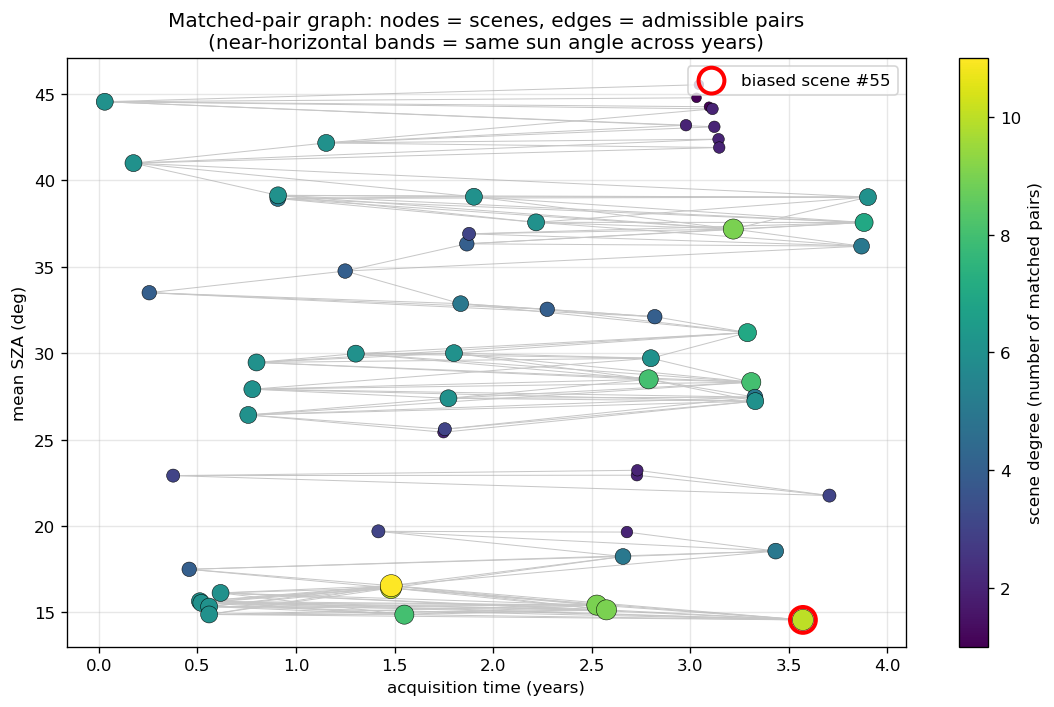

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 6))
segs = [[(t[i], SZA[i]), (t[j], SZA[j])] for (i, j) in edges]
ax.add_collection(LineCollection(segs, colors='0.78', linewidths=0.6, zorder=1))
sizes = 20 + deg*14
sc = ax.scatter(t, SZA, s=sizes, c=deg, cmap='viridis', zorder=2,
                edgecolor='k', linewidth=0.3)
ax.scatter(t[special], SZA[special], s=sizes[special]+80, facecolor='none',
           edgecolor='red', linewidth=2.4, zorder=3, label=f'biased scene #{special}')
plt.colorbar(sc, label='scene degree (number of matched pairs)')
ax.set_xlabel('acquisition time (years)'); ax.set_ylabel('mean SZA (deg)')
ax.set_title('Matched-pair graph: nodes = scenes, edges = admissible pairs\n'
             '(near-horizontal bands = same sun angle across years)')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

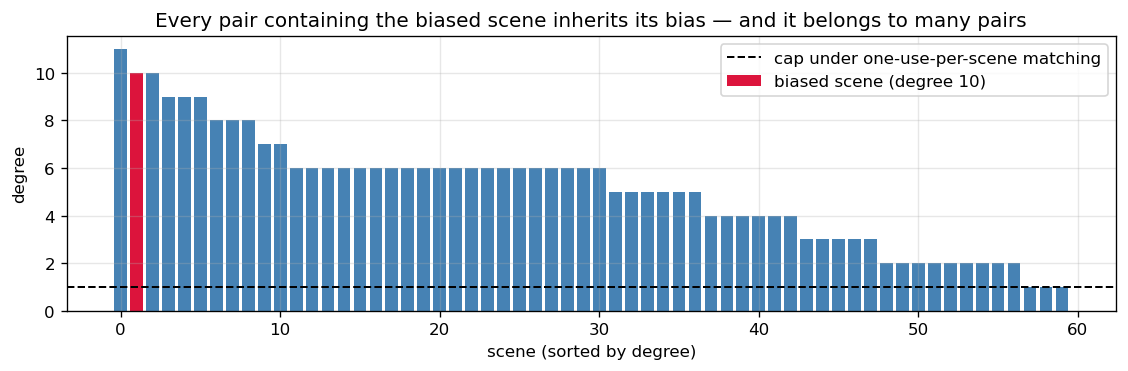

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 3.2))
order = np.argsort(deg)[::-1]
ax.bar(range(N_SCENES), deg[order], color='steelblue')
hp = int(np.where(order == special)[0][0])
ax.bar(hp, deg[special], color='crimson', label=f'biased scene (degree {deg[special]})')
ax.axhline(1, color='k', ls='--', lw=1.2, label='cap under one-use-per-scene matching')
ax.set_xlabel('scene (sorted by degree)'); ax.set_ylabel('degree')
ax.set_title('Every pair containing the biased scene inherits its bias — '
             'and it belongs to many pairs')
ax.legend(); plt.tight_layout(); plt.show()

## 5. Build the per-patch $\Delta R$ table (mirrors the real pipeline)

For every admissible pair we compute $\Delta R = 100\,(R_j-R_i)/R_i$ (%) in **every patch
that saw both scenes**. Because the static surface `b_p` cancels inside a same-patch
difference, $\Delta R \approx (\gamma_\text{true}+\delta_p)\,\Delta t$ plus noise plus any
scene bias. This is the `data/delta_r/per_patch/...` layout: one row per
(pair × patch). The pseudo-replication factor below is how many patch-rows exist per
unique pair.

In [7]:
rows, edge_patches, edge_dt = [], [], []
for (i, j) in edges:
    dt = t[j] - t[i]
    common = np.where(covers[i] & covers[j])[0]
    per = []
    for p in common:
        dR = 100.0*(R[j, p]-R[i, p])/R[i, p]
        rows.append({'i': int(i), 'j': int(j), 'patch': int(p), 'dt_yr': dt,
                     'dR_pct': dR, 'has_special': (i == special or j == special)})
        per.append((int(p), dR))
    edge_patches.append(per)
    edge_dt.append(dt)
per_patch = pd.DataFrame(rows)
edge_dt = np.array(edge_dt)
edge_med = np.array([np.median([d for _, d in per]) for per in edge_patches])

print(f"{len(per_patch)} per-patch delta rows for {len(edges)} unique pairs "
      f"(pseudo-replication factor {len(per_patch)/len(edges):.1f}x)")
per_patch.head()

681 per-patch delta rows for 153 unique pairs (pseudo-replication factor 4.5x)


,i,j,patch,dt_yr,dR_pct,has_special
0,0,41,10,2.949600,-5.974413,False
1,0,42,1,3.002902,-8.453108,False
2,0,42,2,3.002902,-3.900259,False
3,0,42,5,3.002902,-8.400956,False
4,0,42,9,3.002902,-1.456054,False


## 6. The current estimators — and how they fail

- **E1 raw per-patch:** Theil–Sen over *every* patch-row (what happens if you fit the
  per-patch tables directly, `use_aggregated=False`). Maximal pseudo-replication.
- **E2 median-collapse (current default):** one median $\Delta R$ per pair, then Theil–Sen.
- **E2b:** the current default **with the biased scene removed** — a leverage probe.

The 95% intervals from `theilslopes` assume independent points; we print them to expose
how *overconfident* both are. Watch the fully-covering biased scene: in **E1** its pairs
are replicated across all 12 patches, so it bends the slope toward zero; **E2**'s
median-collapse strips that amplification and the robust Theil–Sen largely resists the
point-bias — but its interval stays far too narrow, and it remains fragile to that one
scene (E2b). This is exactly *why* the pipeline defaults to `use_aggregated=True`.

In [8]:
def theil(dR, dt):
    r = theilslopes(dR, dt)              # slope (%/yr) + 95% CI assuming independent pts
    return r[0], r[2], r[3]

s1, lo1, hi1 = theil(per_patch['dR_pct'].values, per_patch['dt_yr'].values)

agg = (per_patch.groupby(['i', 'j'])
       .agg(dR_pct=('dR_pct', 'median'), dt_yr=('dt_yr', 'first')).reset_index())
s2, lo2, hi2 = theil(agg['dR_pct'].values, agg['dt_yr'].values)

keep = ~((agg['i'] == special) | (agg['j'] == special))
s2b, lo2b, hi2b = theil(agg.loc[keep, 'dR_pct'].values, agg.loc[keep, 'dt_yr'].values)

print(f"TRUE gamma               : {GAMMA_TRUE:+.2f} %/yr")
print(f"E1 raw per-patch         : {s1:+.2f}  [{lo1:+.2f}, {hi1:+.2f}]   pseudo-replicated")
print(f"E2 median-collapse       : {s2:+.2f}  [{lo2:+.2f}, {hi2:+.2f}]   CURRENT DEFAULT")
print(f"E2b  drop biased scene   : {s2b:+.2f}  [{lo2b:+.2f}, {hi2b:+.2f}]   leverage probe")

TRUE gamma               : -2.00 %/yr
E1 raw per-patch         : -1.77  [-1.94, -1.59]   pseudo-replicated
E2 median-collapse       : -2.02  [-2.20, -1.82]   CURRENT DEFAULT
E2b  drop biased scene   : -2.13  [-2.31, -1.96]   leverage probe


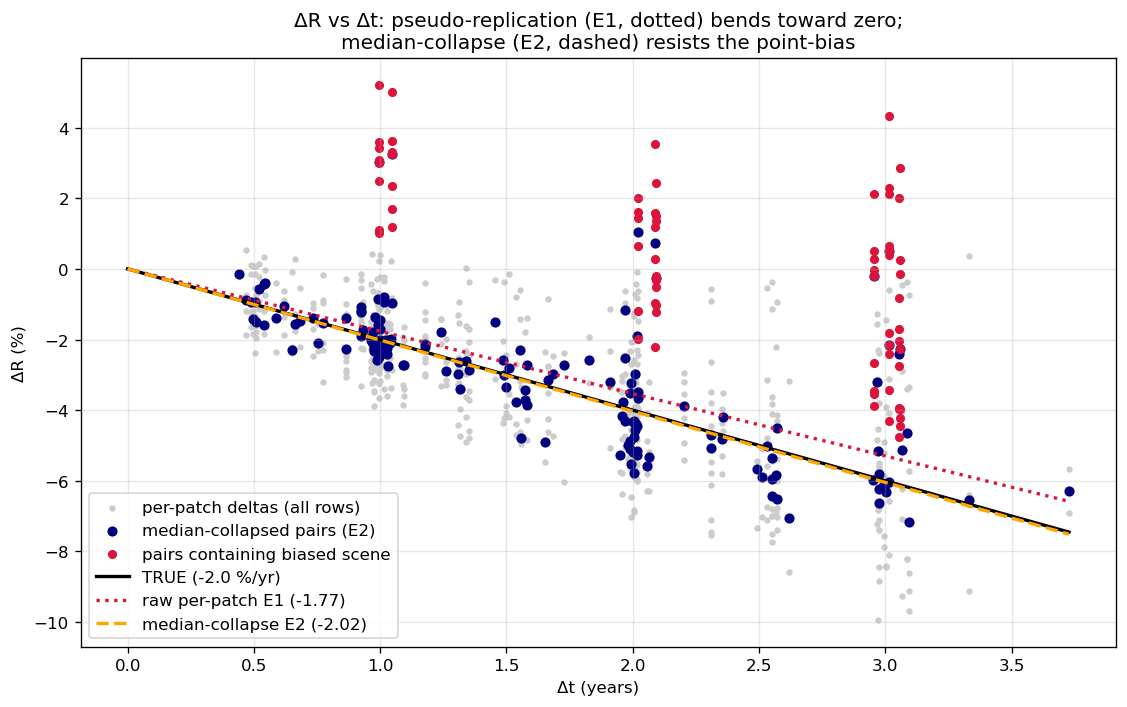

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.scatter(per_patch['dt_yr'], per_patch['dR_pct'], s=8, color='0.8',
           label='per-patch deltas (all rows)')
ax.scatter(agg['dt_yr'], agg['dR_pct'], s=26, color='navy',
           label='median-collapsed pairs (E2)')
sp = per_patch[per_patch['has_special']]
ax.scatter(sp['dt_yr'], sp['dR_pct'], s=20, color='crimson',
           label='pairs containing biased scene')
xx = np.linspace(0, per_patch['dt_yr'].max(), 50)
ax.plot(xx, GAMMA_TRUE*xx, 'k-', lw=2, label=f'TRUE ({GAMMA_TRUE:+.1f} %/yr)')
ax.plot(xx, s1*xx, color='crimson', lw=2, ls=':', label=f'raw per-patch E1 ({s1:+.2f})')
ax.plot(xx, s2*xx, color='orange', lw=2, ls='--', label=f'median-collapse E2 ({s2:+.2f})')
ax.set_xlabel('Δt (years)'); ax.set_ylabel('ΔR (%)')
ax.set_title('ΔR vs Δt: pseudo-replication (E1, dotted) bends toward zero;\n'
             'median-collapse (E2, dashed) resists the point-bias')
ax.legend(); plt.tight_layout(); plt.show()

## 7. The proposed fix — a one-use-per-scene matching

A **matching** is a set of edges with no shared node. Drawing one at random keeps only
pairs that share no scene, so within one fit the pairs are (approximately) independent
and each scene contributes at most once. Different random orders give different
matchings — the raw material for the bootstrap.

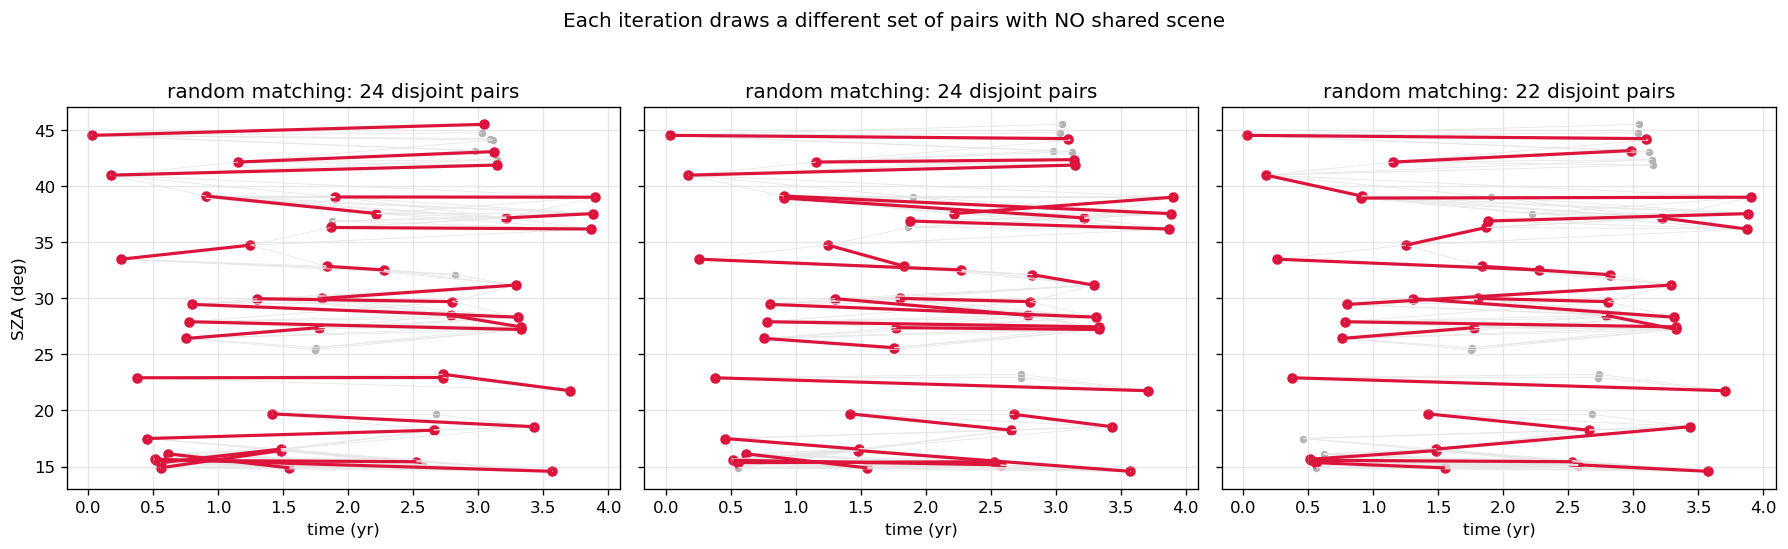

In [10]:
def random_matching(edges, rng):
    """A random maximal matching: shuffle edges, greedily take any whose
    endpoints are both still free. Each scene ends up in at most one pair."""
    order = rng.permutation(len(edges))
    used = np.zeros(N_SCENES, dtype=bool)
    chosen = []
    for e in order:
        i, j = edges[e]
        if not used[i] and not used[j]:
            used[i] = used[j] = True
            chosen.append(e)
    return chosen

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True, sharey=True)
demo_rng = np.random.default_rng(7)
for ax in axes:
    ch = random_matching(edges, demo_rng)
    ax.add_collection(LineCollection(segs, colors='0.9', linewidths=0.5))
    msegs = [[(t[edges[e][0]], SZA[edges[e][0]]),
              (t[edges[e][1]], SZA[edges[e][1]])] for e in ch]
    ax.add_collection(LineCollection(msegs, colors='crimson', linewidths=1.9))
    used = np.unique(edges[ch].ravel())
    ax.scatter(t, SZA, s=12, color='0.7')
    ax.scatter(t[used], SZA[used], s=28, color='crimson')
    ax.set_title(f'random matching: {len(ch)} disjoint pairs')
    ax.set_xlabel('time (yr)')
axes[0].set_ylabel('SZA (deg)')
fig.suptitle('Each iteration draws a different set of pairs with NO shared scene', y=1.03)
plt.tight_layout(); plt.show()

### The bootstrap

For `B` iterations: draw a matching, draw **one patch's** $\Delta R$ per chosen pair
(injecting surface heterogeneity), and fit a Theil–Sen slope. The distribution of the
`B` slopes gives the point estimate (its median) and an honest 95% CI (its 2.5/97.5
percentiles).

We also compute a **variant** that uses the median-$\Delta R$ per edge instead of a
random patch draw — comparing the two isolates exactly how much uncertainty the surface
heterogeneity contributes (defect 2).

In [11]:
B = 1000
boot     = np.empty(B)      # proposed: matching + random patch draw
boot_med = np.empty(B)      # variant: matching, but median dR per edge (no patch draw)

for b in range(B):
    ch   = random_matching(edges, rng)
    dt_b = edge_dt[ch]
    dR_b = np.array([edge_patches[e][rng.integers(len(edge_patches[e]))][1] for e in ch])
    boot[b]     = theilslopes(dR_b, dt_b)[0]
    boot_med[b] = theilslopes(edge_med[ch], dt_b)[0]

def summ(x): return np.median(x), np.percentile(x, 2.5), np.percentile(x, 97.5)
m,  lo,  hi  = summ(boot)
mm, lom, him = summ(boot_med)

print(f"TRUE gamma                          : {GAMMA_TRUE:+.2f} %/yr")
print(f"PROPOSED (match + patch draw)       : {m:+.2f}  [{lo:+.2f}, {hi:+.2f}]  "
      f"(width {hi-lo:.2f})")
print(f"  variant (match, median per edge)  : {mm:+.2f}  [{lom:+.2f}, {him:+.2f}]  "
      f"(width {him-lom:.2f})  <- narrower: surface spread removed")

TRUE gamma                          : -2.00 %/yr
PROPOSED (match + patch draw)       : -1.91  [-2.74, -1.00]  (width 1.74)
  variant (match, median per edge)  : -2.00  [-2.40, -1.58]  (width 0.82)  <- narrower: surface spread removed


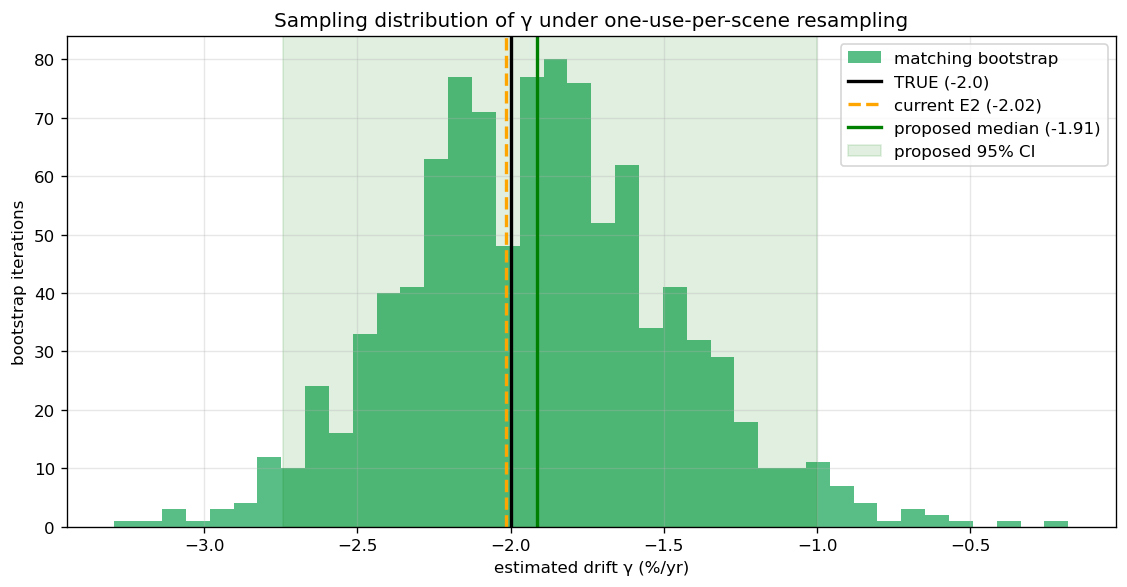

In [12]:
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.hist(boot, bins=40, color='mediumseagreen', alpha=0.85, label='matching bootstrap')
ax.axvline(GAMMA_TRUE, color='k', lw=2, label=f'TRUE ({GAMMA_TRUE:+.1f})')
ax.axvline(s2, color='orange', lw=2, ls='--', label=f'current E2 ({s2:+.2f})')
ax.axvline(m, color='green', lw=2, label=f'proposed median ({m:+.2f})')
ax.axvspan(lo, hi, color='green', alpha=0.12, label='proposed 95% CI')
ax.set_xlabel('estimated drift γ (%/yr)'); ax.set_ylabel('bootstrap iterations')
ax.set_title('Sampling distribution of γ under one-use-per-scene resampling')
ax.legend(); plt.tight_layout(); plt.show()

## 8. Why it works: bounded leverage

Across the `B` matchings, count how often each scene is used. By construction this is a
**fraction ≤ 1** — no scene can dominate any single fit, and the biased scene enters at
most one pair per fit instead of `deg[special]` of them. Its influence is diluted across
iterations rather than baked into many correlated residuals.

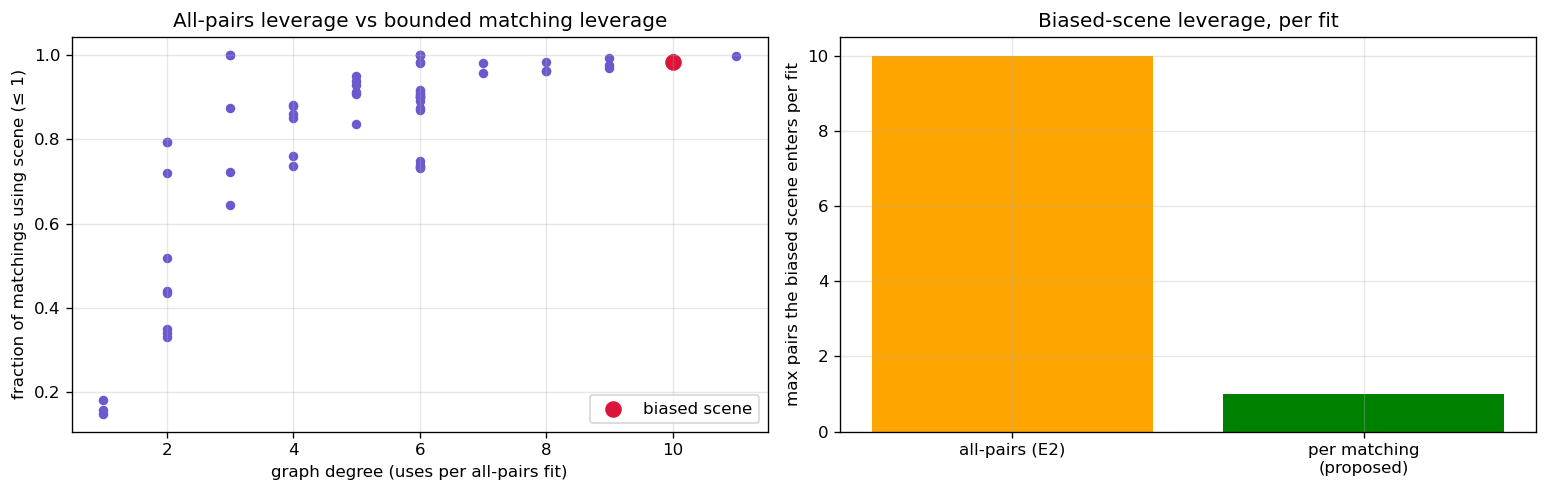

In [13]:
usage = np.zeros(N_SCENES)
u_rng = np.random.default_rng(1)
for b in range(B):
    ch = random_matching(edges, u_rng)
    usage[np.unique(edges[ch].ravel())] += 1
avg_uses = usage / B

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].scatter(deg, avg_uses, s=22, color='slateblue')
ax[0].scatter(deg[special], avg_uses[special], s=80, color='crimson', label='biased scene')
ax[0].set_xlabel('graph degree (uses per all-pairs fit)')
ax[0].set_ylabel('fraction of matchings using scene (≤ 1)')
ax[0].set_title('All-pairs leverage vs bounded matching leverage'); ax[0].legend()
ax[1].bar(['all-pairs (E2)', 'per matching\n(proposed)'], [deg[special], 1],
          color=['orange', 'green'])
ax[1].set_ylabel('max pairs the biased scene enters per fit')
ax[1].set_title('Biased-scene leverage, per fit')
plt.tight_layout(); plt.show()

## 9. Estimator comparison

Point estimate and 95% interval for every estimator against the known truth (red line).
Read it top to bottom: **E1** is both biased toward zero (its pairs are amplified across
all 12 patches the biased scene covers) and absurdly tight — its interval misses the truth.
**E2**'s median-collapse recovers a near-true point estimate (Theil–Sen is robust), but its
interval is still far too narrow (**overconfident**) and removing one scene (E2b) shifts it,
so it stays **fragile**. The **proposed** estimator sits on the truth with an interval wide
enough to actually cover it: honest, not narrow.

*(The headline defect of the naive fits is interval **width** — they claim a precision the
data do not support. E1 additionally shows how pseudo-replication turns one biased scene
into a point-estimate bias.)*

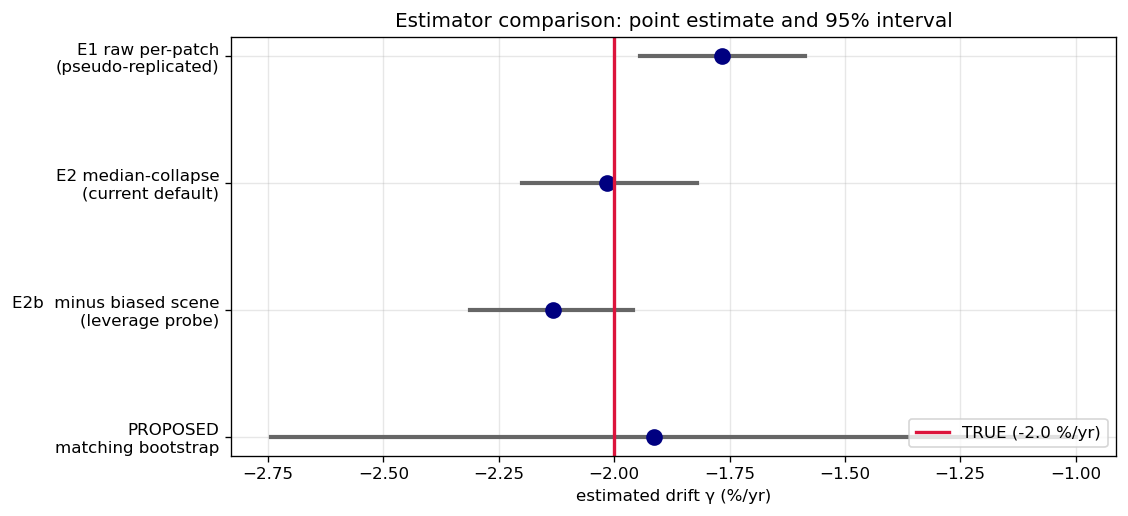

In [14]:
labels = ['E1 raw per-patch\n(pseudo-replicated)',
          'E2 median-collapse\n(current default)',
          'E2b  minus biased scene\n(leverage probe)',
          'PROPOSED\nmatching bootstrap']
est = [s1, s2, s2b, m]; los = [lo1, lo2, lo2b, lo]; his = [hi1, hi2, hi2b, hi]
y = np.arange(len(labels))[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.4))
for k in range(len(labels)):
    ax.plot([los[k], his[k]], [y[k], y[k]], color='0.4', lw=2.5)
    ax.plot(est[k], y[k], 'o', color='navy', ms=9)
ax.axvline(GAMMA_TRUE, color='crimson', lw=2, label=f'TRUE ({GAMMA_TRUE:+.1f} %/yr)')
ax.set_yticks(y); ax.set_yticklabels(labels)
ax.set_xlabel('estimated drift γ (%/yr)'); ax.legend(loc='lower right')
ax.set_title('Estimator comparison: point estimate and 95% interval')
plt.tight_layout(); plt.show()

## 10. Takeaways and how this maps onto the pipeline

**What the demo shows**
- The naive all-pairs / median-collapse fit is **overconfident** (its interval is far too
  narrow because the pairs are not independent) and **fragile** (one biased, over-connected
  scene shifts it materially).
- The **matching bootstrap** recovers the true drift, caps every scene's leverage at one
  pair per fit, and — via the per-patch draw — folds surface heterogeneity into an
  honest, wider confidence interval. It is the same resampling philosophy as the BRDF step.

**How to wire it into the pipeline**
- Replace the current step-7 median-collapse + step-8 Theil–Sen (`drift.use_aggregated`)
  with a new resampling step that consumes the per-patch delta tables directly:
  build the SZA graph per channel, then run `B` matchings with a per-edge patch draw.
- New `run_config.yaml` keys, mirroring `brdf`: `n_bootstrap` (B), a `min_dt_days` edge
  filter, and reuse of `matching.sza_tol`.
- Report per channel: `gamma_median`, `ci_low`, `ci_high` (percentiles), and a bootstrap
  p-value (does the CI exclude 0) in place of Kendall+BH.

**Honest caveats**
- Each matching uses only ~half the scenes; large `B` recovers the lost efficiency.
- This conditions on the *observed* scene set (it captures pairing + surface uncertainty,
  not "what if we'd observed other scenes"). For that, wrap an outer scene bootstrap
  (resample scenes with replacement, rematch inside).
- Real runs loop this over every EMIT channel; here we used one synthetic channel for
  clarity.
- Parameters here were tuned to make the effects legible, not to mimic any specific PICS.